#### **1. Import Library**

In [16]:
import json
import sys
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC, SVC

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Menentukan folder utama project.
candidate_roots = [Path.cwd(), *Path.cwd().parents]

PROJECT_ROOT = next(
    (
        path.resolve()
        for path in candidate_roots
        if (path / "scripts" / "preprocess.py").exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Folder scripts tidak ditemukan. "
        "Pastikan notebook berada di dalam project."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.preprocess import (
    infer_target_column,
    detect_id_columns,
    identify_feature_types,
    build_preprocessor
)

from scripts.feature_engineering import engineer_features

print("Project root:", PROJECT_ROOT)
print("Import scripts berhasil.")

Project root: D:\SAINS DATA ITS\SEMESTER 5\Supervised Machine Learning\structural-damage-classification
Import scripts berhasil.


#### **2. Load Dataset**

In [17]:
DATA_DIR = PROJECT_ROOT / "data"

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"
SAMPLE_PATH = DATA_DIR / "sample_submission.csv"

for path in [TRAIN_PATH, TEST_PATH]:
    if not path.exists():
        raise FileNotFoundError(
            f"Dataset tidak ditemukan: {path}"
        )

train_df = pd.read_csv(TRAIN_PATH, low_memory=False)
test_df = pd.read_csv(TEST_PATH, low_memory=False)

sample_submission = (
    pd.read_csv(SAMPLE_PATH)
    if SAMPLE_PATH.exists()
    else None
)

TARGET_COLUMN = infer_target_column(
    train_df,
    test_df,
    sample_submission
)

print("Target:", TARGET_COLUMN)
print("Train:", train_df.shape)
print("Test :", test_df.shape)

display(train_df.head())

Target: damage_grade
Train: (533465, 17)
Test : (228629, 16)


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone


#### **3. Data Preparation**

In [18]:
y = train_df[TARGET_COLUMN].copy()

valid_target_mask = y.notna()

print("Baris tanpa target:", int((~valid_target_mask).sum()))

X_raw = train_df.drop(
    columns=[TARGET_COLUMN]
).loc[valid_target_mask].copy()

y = y.loc[valid_target_mask].copy()

X_raw = X_raw.reset_index(drop=True)
y = y.reset_index(drop=True)

ID_COLUMNS = detect_id_columns(X_raw)

FEATURE_COLUMNS = [
    col for col in X_raw.columns
    if col not in ID_COLUMNS
]

missing_test_features = [
    col for col in FEATURE_COLUMNS
    if col not in test_df.columns
]

if missing_test_features:
    raise ValueError(
        f"Fitur training tidak ditemukan pada test: "
        f"{missing_test_features}"
    )

X = engineer_features(
    X_raw[FEATURE_COLUMNS],
    expected_columns=FEATURE_COLUMNS
)

print("Jumlah data berlabel:", len(X))
print("Jumlah fitur:", len(FEATURE_COLUMNS))
print("ID columns:", ID_COLUMNS)

display(y.value_counts().to_frame("Jumlah"))

Baris tanpa target: 0
Jumlah data berlabel: 533465
Jumlah fitur: 15
ID columns: ['building_id']


,Jumlah
damage_grade,
Grade 5,193036
Grade 4,128691
Grade 3,95488
Grade 2,61080
Grade 1,55170


#### **4. Identifikasi Tipe Fitur**

In [19]:
numerical_columns, categorical_columns = identify_feature_types(X)

print("Fitur numerik:", numerical_columns)
print("Fitur kategorik:", categorical_columns)

if not numerical_columns and not categorical_columns:
    raise ValueError(
        "Tidak ada fitur numerik atau kategorik untuk modeling."
    )

Fitur numerik: ['age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq']
Fitur kategorik: ['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'superstructure', 'district_id', 'vdcmun_id', 'ward_id', 'count_floors_pre_eq']


#### **5. Dataset Splitting dan Preprocessing**

In [20]:
minimum_class_count = y.value_counts().min()
number_of_classes = y.nunique()

validation_size = int(np.ceil(0.2 * len(y)))
training_size = len(y) - validation_size

use_stratify = (
    minimum_class_count >= 2
    and validation_size >= number_of_classes
    and training_size >= number_of_classes
)

stratify_target = y if use_stratify else None

if not use_stratify:
    print("Peringatan: stratifikasi tidak dapat digunakan.")

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=stratify_target
)

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)

X_train: (426772, 15)
X_valid: (106693, 15)
y_train: (426772,)
y_valid: (106693,)


#### **6. Baseline Model Training**

In [21]:
baseline_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced",
        min_samples_leaf=2
    ),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        max_iter=5000,
        random_state=42,
        dual="auto"
    )
}

# SVC RBF dapat membutuhkan komputasi besar.
if len(X_train) <= 10000:
    baseline_models["SVM RBF"] = SVC(
        kernel="rbf",
        class_weight="balanced"
    )
else:
    print(
        "SVM RBF dilewati karena ukuran data terlalu besar. "
        "Linear SVM digunakan sebagai alternatif yang lebih skalabel."
    )

baseline_results = []
fitted_models = {}

for model_name, estimator in baseline_models.items():
    print(f"\nTraining: {model_name}")

    model_pipeline = Pipeline([
        (
            "prep",
            build_preprocessor(
                numerical_columns,
                categorical_columns
            )
        ),
        ("algo", estimator)
    ])

    start_time = time.time()

    model_pipeline.fit(X_train, y_train)

    y_pred = model_pipeline.predict(X_valid)

    elapsed_time = time.time() - start_time

    macro_f1 = f1_score(
        y_valid,
        y_pred,
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(y_valid, y_pred)

    baseline_results.append({
        "Model": model_name,
        "Macro F1": macro_f1,
        "Accuracy": accuracy,
        "Waktu (detik)": elapsed_time
    })

    fitted_models[model_name] = model_pipeline

    print(f"Macro F1 : {macro_f1:.4f}")
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Waktu    : {elapsed_time:.2f} detik")

SVM RBF dilewati karena ukuran data terlalu besar. Linear SVM digunakan sebagai alternatif yang lebih skalabel.

Training: Logistic Regression
Macro F1 : 0.5078
Accuracy : 0.5393
Waktu    : 112.72 detik

Training: Decision Tree
Macro F1 : 0.4636
Accuracy : 0.4871
Waktu    : 272.00 detik

Training: Linear SVM
Macro F1 : 0.5025
Accuracy : 0.5445
Waktu    : 169.28 detik


#### **7. Evaluasi dan Perbandingan Baseline**

,Model,Macro F1,Accuracy,Waktu (detik)
0,Logistic Regression,0.507777,0.539304,112.720906
1,Linear SVM,0.502451,0.544516,169.279082
2,Decision Tree,0.463560,0.487117,271.999746


Baseline terbaik: Logistic Regression
Validation Macro F1: 0.5078

Classification Report:
              precision    recall  f1-score   support

     Grade 1       0.53      0.74      0.62     11034
     Grade 2       0.32      0.38      0.34     12216
     Grade 3       0.39      0.38      0.39     19098
     Grade 4       0.49      0.48      0.48     25738
     Grade 5       0.77      0.65      0.70     38607

    accuracy                           0.54    106693
   macro avg       0.50      0.53      0.51    106693
weighted avg       0.56      0.54      0.54    106693



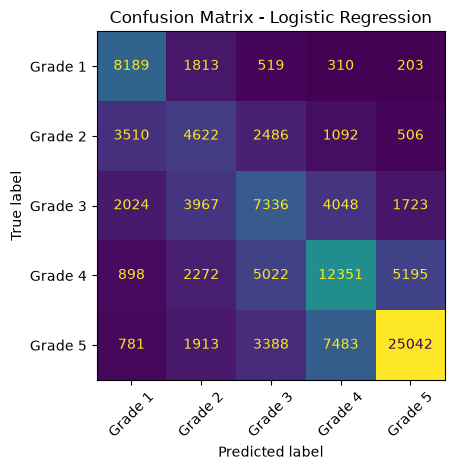

In [22]:
results_df = pd.DataFrame(
    baseline_results
).sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

display(results_df)

best_baseline_name = results_df.loc[0, "Model"]
best_baseline_f1 = float(
    results_df.loc[0, "Macro F1"]
)

best_baseline_model = fitted_models[
    best_baseline_name
]

print("Baseline terbaik:", best_baseline_name)
print(f"Validation Macro F1: {best_baseline_f1:.4f}")

baseline_pred = best_baseline_model.predict(X_valid)

print("\nClassification Report:")
print(
    classification_report(
        y_valid,
        baseline_pred,
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    baseline_pred,
    xticks_rotation=45,
    colorbar=False
)

plt.title(f"Confusion Matrix - {best_baseline_name}")
plt.tight_layout()
plt.show()

#### **8. Hyperparameter Tuning**

In [23]:
# Mengambil subset training untuk mempercepat tuning.
TUNE_FRACTION = 0.15

stratify_tune = (
    y_train
    if y_train.value_counts().min() >= 2
    else None
)

X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=TUNE_FRACTION,
    random_state=42,
    stratify=stratify_tune
)

cv_splits = min(
    3,
    int(y_tune.value_counts().min())
)

if cv_splits < 2:
    raise ValueError(
        "Jumlah sampel pada subset tuning tidak cukup "
        "untuk cross-validation."
    )

print("Data tuning:", X_tune.shape)
print("Jumlah CV folds:", cv_splits)


# Ruang pencarian parameter untuk model materi dosen.
course_param_grids = {
    "Logistic Regression": [
        {
            "algo__C": [0.1],
            "algo__class_weight": [None]
        },
        {
            "algo__C": [1.0],
            "algo__class_weight": [None]
        },
        {
            "algo__C": [1.0],
            "algo__class_weight": ["balanced"]
        },
        {
            "algo__C": [10.0],
            "algo__class_weight": ["balanced"]
        }
    ],

    "Decision Tree": [
        {
            "algo__max_depth": [15],
            "algo__min_samples_leaf": [2],
            "algo__class_weight": [None]
        },
        {
            "algo__max_depth": [30],
            "algo__min_samples_leaf": [2],
            "algo__class_weight": [None]
        },
        {
            "algo__max_depth": [None],
            "algo__min_samples_leaf": [2],
            "algo__class_weight": [None]
        },
        {
            "algo__max_depth": [20],
            "algo__min_samples_leaf": [5],
            "algo__class_weight": ["balanced"]
        }
    ],

    "Linear SVM": [
        {
            "algo__C": [0.1],
            "algo__class_weight": ["balanced"]
        },
        {
            "algo__C": [1.0],
            "algo__class_weight": ["balanced"]
        },
        {
            "algo__C": [1.0],
            "algo__class_weight": [None]
        }
    ]
}


tuned_models = {}
tuned_results = []

# Estimator yang digunakan sudah didefinisikan
# pada Cell 6 sebelumnya.
course_model_names = [
    "Logistic Regression",
    "Decision Tree",
    "Linear SVM"
]

for model_name in course_model_names:
    print(f"\nTuning {model_name}")
    start_time = time.time()

    pipeline = Pipeline([
        (
            "prep",
            build_preprocessor(
                numerical_columns,
                categorical_columns
            )
        ),
        (
            "algo",
            clone(baseline_models[model_name])
        )
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=course_param_grids[model_name],
        scoring="f1_macro",
        cv=cv_splits,
        n_jobs=1,
        refit=False,
        verbose=1
    )

    search.fit(X_tune, y_tune)

    # Melatih ulang konfigurasi terbaik pada seluruh X_train.
    tuned_pipeline = Pipeline([
        (
            "prep",
            build_preprocessor(
                numerical_columns,
                categorical_columns
            )
        ),
        (
            "algo",
            clone(baseline_models[model_name])
        )
    ])

    tuned_pipeline.set_params(**search.best_params_)
    tuned_pipeline.fit(X_train, y_train)

    y_pred = tuned_pipeline.predict(X_valid)

    macro_f1 = f1_score(
        y_valid,
        y_pred,
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(y_valid, y_pred)
    elapsed_time = time.time() - start_time

    tuned_name = f"{model_name} (Tuned)"

    tuned_models[tuned_name] = tuned_pipeline

    tuned_results.append({
        "Model": tuned_name,
        "CV Macro F1": search.best_score_,
        "Macro F1": macro_f1,
        "Accuracy": accuracy,
        "Waktu (detik)": elapsed_time,
        "Best Parameters": search.best_params_
    })

    print("Best parameters:", search.best_params_)
    print(f"CV Macro F1     : {search.best_score_:.4f}")
    print(f"Validation F1   : {macro_f1:.4f}")
    print(f"Accuracy        : {accuracy:.4f}")

Data tuning: (64015, 15)
Jumlah CV folds: 3

Tuning Logistic Regression
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'algo__C': 10.0, 'algo__class_weight': 'balanced'}
CV Macro F1     : 0.4950
Validation F1   : 0.5079
Accuracy        : 0.5392

Tuning Decision Tree
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'algo__class_weight': 'balanced', 'algo__max_depth': 20, 'algo__min_samples_leaf': 5}
CV Macro F1     : 0.4440
Validation F1   : 0.4690
Accuracy        : 0.4919

Tuning Linear SVM
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best parameters: {'algo__C': 1.0, 'algo__class_weight': 'balanced'}
CV Macro F1     : 0.4911
Validation F1   : 0.5025
Accuracy        : 0.5445


#### **9. Evaluasi Hasil Tuning**

In [24]:
baseline_comparison = results_df[
    ["Model", "Macro F1", "Accuracy", "Waktu (detik)"]
].copy()

baseline_comparison["Tahap"] = "Baseline"

tuned_comparison = pd.DataFrame(tuned_results)[
    ["Model", "Macro F1", "Accuracy", "Waktu (detik)"]
].copy()

tuned_comparison["Tahap"] = "Tuning"

course_comparison = pd.concat(
    [baseline_comparison, tuned_comparison],
    ignore_index=True
)

course_comparison = course_comparison.sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

display(course_comparison)

baseline_lr_f1 = results_df.loc[
    results_df["Model"] == "Logistic Regression",
    "Macro F1"
].iloc[0]

best_course_row = course_comparison.iloc[0]

print("\nModel terbaik sejauh ini:", best_course_row["Model"])
print(f"Validation Macro F1: {best_course_row['Macro F1']:.4f}")
print(f"Baseline Logistic Regression: {baseline_lr_f1:.4f}")

print(
    "Selisih dari baseline awal:",
    f"{best_course_row['Macro F1'] - baseline_lr_f1:+.4f}"
)

,Model,Macro F1,Accuracy,Waktu (detik),Tahap
0,Logistic Regression (Tuned),0.507869,0.539173,194.120379,Tuning
1,Logistic Regression,0.507777,0.539304,112.720906,Baseline
2,Linear SVM,0.502451,0.544516,169.279082,Baseline
3,Linear SVM (Tuned),0.502451,0.544516,221.900353,Tuning
4,Decision Tree (Tuned),0.469033,0.491897,87.966122,Tuning
5,Decision Tree,0.463560,0.487117,271.999746,Baseline



Model terbaik sejauh ini: Logistic Regression (Tuned)
Validation Macro F1: 0.5079
Baseline Logistic Regression: 0.5078
Selisih dari baseline awal: +0.0001


#### **10. Random Forest**

In [25]:
from sklearn.ensemble import RandomForestClassifier

rf_base = RandomForestClassifier(
    n_estimators=60,
    max_features="sqrt",
    random_state=42,
    n_jobs=1
)

rf_pipeline = Pipeline([
    (
        "prep",
        build_preprocessor(
            numerical_columns,
            categorical_columns
        )
    ),
    ("algo", rf_base)
])

rf_param_grid = [
    {
        "algo__max_depth": [20],
        "algo__min_samples_leaf": [2],
        "algo__class_weight": [None]
    },
    {
        "algo__max_depth": [30],
        "algo__min_samples_leaf": [2],
        "algo__class_weight": [None]
    },
    {
        "algo__max_depth": [20],
        "algo__min_samples_leaf": [5],
        "algo__class_weight": ["balanced"]
    }
]

print("Memulai tuning Random Forest...")
rf_start_time = time.time()

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring="f1_macro",
    cv=cv_splits,
    n_jobs=1,
    refit=False,
    verbose=1
)

rf_search.fit(X_tune, y_tune)

print("\nBest parameters:")
print(rf_search.best_params_)

print(f"CV Macro F1: {rf_search.best_score_:.4f}")

# Melatih ulang menggunakan seluruh data training.
rf_model = Pipeline([
    (
        "prep",
        build_preprocessor(
            numerical_columns,
            categorical_columns
        )
    ),
    (
        "algo",
        clone(rf_base)
    )
])

rf_model.set_params(**rf_search.best_params_)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_valid)

rf_macro_f1 = f1_score(
    y_valid,
    rf_pred,
    average="macro",
    zero_division=0
)

rf_accuracy = accuracy_score(
    y_valid,
    rf_pred
)

rf_elapsed = time.time() - rf_start_time

rf_validation_result = {
    "Model": "Random Forest",
    "CV Macro F1": rf_search.best_score_,
    "Macro F1": rf_macro_f1,
    "Accuracy": rf_accuracy,
    "Waktu (detik)": rf_elapsed
}

print(f"\nValidation Macro F1: {rf_macro_f1:.4f}")
print(f"Accuracy: {rf_accuracy:.4f}")
print(f"Waktu: {rf_elapsed:.2f} detik")

Memulai tuning Random Forest...
Fitting 3 folds for each of 3 candidates, totalling 9 fits

Best parameters:
{'algo__class_weight': 'balanced', 'algo__max_depth': 20, 'algo__min_samples_leaf': 5}
CV Macro F1: 0.4462

Validation Macro F1: 0.4581
Accuracy: 0.5081
Waktu: 255.54 detik


#### **11.  LightGBM**

In [26]:
from lightgbm import (
    LGBMClassifier,
    early_stopping,
    log_evaluation
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.base import clone
import time
import pandas as pd

# Simpan model terbaik sebelum eksperimen baru.
# Menyiapkan subset tuning jika belum tersedia.
if "X_tune" not in globals():
    stratify_tune = (
        y_train
        if y_train.value_counts().min() >= 2
        else None
    )

    X_tune, _, y_tune, _ = train_test_split(
        X_train,
        y_train,
        train_size=0.15,
        random_state=42,
        stratify=stratify_tune
    )

# Memulihkan baseline LightGBM dari konfigurasi terbaik sebelumnya.
previous_params = {
    "n_estimators": 500,
    "learning_rate": 0.08,
    "num_leaves": 63,
    "max_depth": 15,
    "min_child_samples": 20,
    "subsample": 1.0,
    "subsample_freq": 1,
    "colsample_bytree": 1.0,
    "reg_lambda": 0,
    "class_weight": "balanced"
}

previous_lgbm_model = Pipeline([
    (
        "prep",
        build_preprocessor(
            numerical_columns,
            categorical_columns
        )
    ),
    (
        "algo",
        LGBMClassifier(
            objective="multiclass",
            random_state=42,
            n_jobs=-1,
            verbosity=-1,
            **previous_params
        )
    )
])

previous_lgbm_model.fit(X_train, y_train)

previous_pred = previous_lgbm_model.predict(X_valid)

previous_lgbm_f1 = f1_score(
    y_valid,
    previous_pred,
    average="macro",
    zero_division=0
)

previous_lgbm_result = {
    "Model": "LightGBM",
    "CV Macro F1": 0.509347,
    "Macro F1": previous_lgbm_f1,
    "Accuracy": accuracy_score(y_valid, previous_pred),
    "Waktu (detik)": None
}

print(f"Baseline LightGBM: {previous_lgbm_f1:.6f}")

# Memecah subset tuning untuk early stopping.
X_fit, X_stop, y_fit, y_stop = train_test_split(
    X_tune,
    y_tune,
    test_size=0.20,
    random_state=43,
    stratify=y_tune
)

# Preprocessing hanya dipelajari dari data fitting internal.
refined_preprocessor = build_preprocessor(
    numerical_columns,
    categorical_columns
)

X_fit_encoded = refined_preprocessor.fit_transform(X_fit)
X_stop_encoded = refined_preprocessor.transform(X_stop)

# Empat konfigurasi terarah.
lgbm_configs = [
    {
        "n_estimators": 700,
        "learning_rate": 0.08,
        "num_leaves": 63,
        "max_depth": 15,
        "min_child_samples": 20,
        "subsample": 1.0,
        "subsample_freq": 1,
        "colsample_bytree": 1.0,
        "reg_lambda": 0,
        "class_weight": "balanced"
    },
    {
        "n_estimators": 900,
        "learning_rate": 0.05,
        "num_leaves": 63,
        "max_depth": 15,
        "min_child_samples": 50,
        "subsample": 0.8,
        "subsample_freq": 1,
        "colsample_bytree": 0.8,
        "reg_lambda": 1,
        "class_weight": "balanced"
    },
    {
        "n_estimators": 900,
        "learning_rate": 0.05,
        "num_leaves": 31,
        "max_depth": 10,
        "min_child_samples": 50,
        "subsample": 0.8,
        "subsample_freq": 1,
        "colsample_bytree": 0.8,
        "reg_lambda": 1,
        "class_weight": "balanced"
    },
    {
        "n_estimators": 900,
        "learning_rate": 0.05,
        "num_leaves": 63,
        "max_depth": 15,
        "min_child_samples": 50,
        "subsample": 0.9,
        "subsample_freq": 1,
        "colsample_bytree": 0.9,
        "reg_lambda": 5,
        "class_weight": None
    }
]

experiment_results = []
best_iteration = None
best_config = None
best_internal_f1 = -1

start_time = time.time()

for i, params in enumerate(lgbm_configs, start=1):
    print(f"\nKonfigurasi {i}/{len(lgbm_configs)}")

    candidate = LGBMClassifier(
        objective="multiclass",
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
        **params
    )

    candidate.fit(
        X_fit_encoded,
        y_fit,
        eval_set=[(X_stop_encoded, y_stop)],
        eval_metric="multi_logloss",
        callbacks=[
            early_stopping(
                stopping_rounds=50,
                verbose=False
            ),
            log_evaluation(period=0)
        ]
    )

    pred_stop = candidate.predict(X_stop_encoded)

    internal_f1 = f1_score(
        y_stop,
        pred_stop,
        average="macro",
        zero_division=0
    )

    current_iteration = (
        candidate.best_iteration_
        if candidate.best_iteration_ > 0
        else params["n_estimators"]
    )

    experiment_results.append({
        "Konfigurasi": i,
        "Macro F1 internal": internal_f1,
        "Best iteration": current_iteration
    })

    print(f"Macro F1 internal: {internal_f1:.6f}")
    print(f"Best iteration: {current_iteration}")

    if internal_f1 > best_internal_f1:
        best_internal_f1 = internal_f1
        best_iteration = current_iteration
        best_config = params.copy()

display(pd.DataFrame(experiment_results))

print("\nKonfigurasi terpilih:")
print(best_config)
print("Best iteration:", best_iteration)

# Latih ulang pada seluruh training split.
final_params = best_config.copy()
final_params["n_estimators"] = max(1, int(best_iteration))

candidate_lgbm_model = Pipeline([
    (
        "prep",
        build_preprocessor(
            numerical_columns,
            categorical_columns
        )
    ),
    (
        "algo",
        LGBMClassifier(
            objective="multiclass",
            random_state=42,
            n_jobs=-1,
            verbosity=-1,
            **final_params
        )
    )
])

candidate_lgbm_model.fit(X_train, y_train)

candidate_pred = candidate_lgbm_model.predict(X_valid)

candidate_f1 = f1_score(
    y_valid,
    candidate_pred,
    average="macro",
    zero_division=0
)

candidate_accuracy = accuracy_score(
    y_valid,
    candidate_pred
)

elapsed_time = time.time() - start_time

print(f"\nMacro F1 sebelumnya: {previous_lgbm_f1:.6f}")
print(f"Macro F1 eksperimen: {candidate_f1:.6f}")
print(f"Waktu eksperimen: {elapsed_time:.2f} detik")

# Pertahankan model lama jika hasil baru tidak meningkat.
if candidate_f1 > previous_lgbm_f1:
    lgbm_model = candidate_lgbm_model

    lgbm_validation_result = {
        "Model": "LightGBM",
        "CV Macro F1": None,
        "Macro F1": candidate_f1,
        "Accuracy": candidate_accuracy,
        "Waktu (detik)": elapsed_time
    }

    print("\nModel baru menjadi LightGBM terbaik.")
else:
    lgbm_model = previous_lgbm_model
    lgbm_validation_result = previous_lgbm_result

    print("\nTidak ada peningkatan. Model sebelumnya dipertahankan.")

lgbm_pred = lgbm_model.predict(X_valid)

lgbm_macro_f1 = f1_score(
    y_valid,
    lgbm_pred,
    average="macro",
    zero_division=0
)

lgbm_accuracy = accuracy_score(y_valid, lgbm_pred)

print(f"\nMacro F1 terbaik: {lgbm_macro_f1:.6f}")
print(f"Accuracy terbaik: {lgbm_accuracy:.6f}")

Baseline LightGBM: 0.538860

Konfigurasi 1/4


d:\SAINS DATA ITS\SEMESTER 5\Supervised Machine Learning\structural-damage-classification\project_sml\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Macro F1 internal: 0.509976
Best iteration: 346

Konfigurasi 2/4


d:\SAINS DATA ITS\SEMESTER 5\Supervised Machine Learning\structural-damage-classification\project_sml\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Macro F1 internal: 0.502746
Best iteration: 578

Konfigurasi 3/4


...

Macro F1 internal: 0.499200
Best iteration: 896

Konfigurasi 4/4


d:\SAINS DATA ITS\SEMESTER 5\Supervised Machine Learning\structural-damage-classification\project_sml\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Macro F1 internal: 0.496855
Best iteration: 572


,Konfigurasi,Macro F1 internal,Best iteration
0,1,0.509976,346
1,2,0.502746,578
2,3,0.499200,896
3,4,0.496855,572



Konfigurasi terpilih:
{'n_estimators': 700, 'learning_rate': 0.08, 'num_leaves': 63, 'max_depth': 15, 'min_child_samples': 20, 'subsample': 1.0, 'subsample_freq': 1, 'colsample_bytree': 1.0, 'reg_lambda': 0, 'class_weight': 'balanced'}
Best iteration: 346

Macro F1 sebelumnya: 0.538860
Macro F1 eksperimen: 0.533940
Waktu eksperimen: 241.09 detik

Tidak ada peningkatan. Model sebelumnya dipertahankan.

Macro F1 terbaik: 0.538860
Accuracy terbaik: 0.567207


#### **12. Perbandingan Model dan Pemilihan Model Terbaik**

,Model,CV Macro F1,Macro F1,Accuracy,Waktu (detik)
0,LightGBM,0.509347,0.538860,0.567207,None
1,Logistic Regression (Tuned),0.494993,0.507869,0.539173,194.120379
2,Logistic Regression,NaN,0.507777,0.539304,112.720906
3,Linear SVM,NaN,0.502451,0.544516,169.279082
4,Linear SVM (Tuned),0.491068,0.502451,0.544516,221.900353
5,Decision Tree (Tuned),0.443997,0.469033,0.491897,87.966122
6,Decision Tree,NaN,0.463560,0.487117,271.999746
7,Random Forest,0.446190,0.458102,0.508140,255.544836



Model terpilih: LightGBM
Validation Macro F1: 0.538860
Baseline Logistic Regression: 0.507777
Selisih Macro F1: +0.031082

Classification Report:
              precision    recall  f1-score   support

     Grade 1       0.57      0.78      0.66     11034
     Grade 2       0.36      0.43      0.39     12216
     Grade 3       0.42      0.40      0.41     19098
     Grade 4       0.52      0.51      0.51     25738
     Grade 5       0.78      0.67      0.72     38607

    accuracy                           0.57    106693
   macro avg       0.53      0.56      0.54    106693
weighted avg       0.58      0.57      0.57    106693



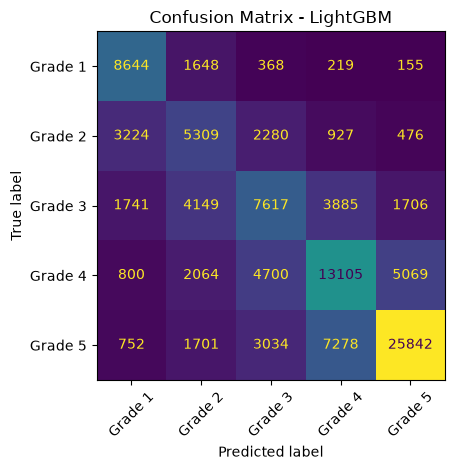

In [27]:
baseline_results_table = results_df[
    ["Model", "Macro F1", "Accuracy", "Waktu (detik)"]
].copy()

baseline_results_table["CV Macro F1"] = np.nan

tuned_results_table = pd.DataFrame(tuned_results)

rf_results_table = pd.DataFrame([
    rf_validation_result
])

lgbm_results_table = pd.DataFrame([
    lgbm_validation_result
])

all_results = pd.concat(
    [
        baseline_results_table,
        tuned_results_table,
        rf_results_table,
        lgbm_results_table
    ],
    ignore_index=True,
    sort=False
)

all_results = all_results.sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

display(
    all_results[
        [
            "Model",
            "CV Macro F1",
            "Macro F1",
            "Accuracy",
            "Waktu (detik)"
        ]
    ]
)

candidate_models = dict(fitted_models)
candidate_models.update(tuned_models)
candidate_models["Random Forest"] = rf_model
candidate_models["LightGBM"] = lgbm_model

best_model_name = all_results.loc[0, "Model"]

best_validation_f1 = float(
    all_results.loc[0, "Macro F1"]
)

best_validation_model = candidate_models[
    best_model_name
]

baseline_lr_f1 = float(
    results_df.loc[
        results_df["Model"] == "Logistic Regression",
        "Macro F1"
    ].iloc[0]
)

print("\nModel terpilih:", best_model_name)
print(f"Validation Macro F1: {best_validation_f1:.6f}")
print(f"Baseline Logistic Regression: {baseline_lr_f1:.6f}")
print(
    f"Selisih Macro F1: "
    f"{best_validation_f1 - baseline_lr_f1:+.6f}"
)

best_pred = best_validation_model.predict(X_valid)

print("\nClassification Report:")
print(
    classification_report(
        y_valid,
        best_pred,
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    best_pred,
    xticks_rotation=45,
    colorbar=False
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

#### **13. Training Final dan Penyimpanan Model**

In [28]:
import json
import joblib
from pathlib import Path
from sklearn.pipeline import Pipeline
from lightgbm import LGBMClassifier

# Konfigurasi LightGBM terbaik yang telah dievaluasi.
final_params = {
    "n_estimators": 500,
    "learning_rate": 0.08,
    "num_leaves": 63,
    "max_depth": 15,
    "min_child_samples": 20,
    "subsample": 1.0,
    "subsample_freq": 1,
    "colsample_bytree": 1.0,
    "reg_lambda": 0,
    "class_weight": "balanced"
}

# Membuat pipeline model final.
final_model = Pipeline([
    (
        "prep",
        build_preprocessor(
            numerical_columns,
            categorical_columns
        )
    ),
    (
        "algo",
        LGBMClassifier(
            objective="multiclass",
            random_state=42,
            n_jobs=-1,
            verbosity=-1,
            **final_params
        )
    )
])

# Training dengan seluruh data berlabel.
final_model.fit(X, y)

# Menyiapkan folder penyimpanan.
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "final_damage_model.joblib"
METADATA_PATH = MODEL_DIR / "model_metadata.json"

# Menyimpan model.
joblib.dump(final_model, MODEL_PATH)

# Menyimpan metadata.
metadata = {
    "target_column": TARGET_COLUMN,
    "feature_columns": FEATURE_COLUMNS,
    "id_columns": ID_COLUMNS,
    "best_model_name": "LightGBM",
    "validation_macro_f1": 0.538860,
    "baseline_macro_f1": 0.507869,
    "model_params": final_params
}

with open(METADATA_PATH, "w", encoding="utf-8") as file:
    json.dump(
        metadata,
        file,
        indent=2,
        ensure_ascii=False
    )

print("Model final berhasil disimpan.")
print("Model:", MODEL_PATH)
print("Metadata:", METADATA_PATH)
print("Model terpilih: LightGBM")
print("Validation Macro F1: 0.538860")

Model final berhasil disimpan.
Model: D:\SAINS DATA ITS\SEMESTER 5\Supervised Machine Learning\structural-damage-classification\models\final_damage_model.joblib
Metadata: D:\SAINS DATA ITS\SEMESTER 5\Supervised Machine Learning\structural-damage-classification\models\model_metadata.json
Model terpilih: LightGBM
Validation Macro F1: 0.538860
